# Preprocessing Test Notebook

Ce notebook sert à **tester** et **valider** chaque étape du preprocessing du dataset **FER(2013)** avant de transformer le pipeline en script Python automatisé **(.py)**.

# Structure du notebook
1.   Load dataset
2.   Visualisation des images
3.   Preprocessing (normalisation, reshape)
4.   Encoding Labels
5.   Train/val/test split
6.   Vérification des résultats



# 1. Chargement du dataset



In [ ]:
import pandas as pd

In [ ]:
# Chemin de base vers le dossier principal du projet (Google Drive)
base_path = '/content/drive/MyDrive/emotion-detection/'

# Définir le chemin du fichier CSV contenant le dataset FER2013
csv_path = base_path + 'data/raw/fer2013.csv'

# Charger le dataset FER2013 dans un DataFrame pandas
df = pd.read_csv(csv_path)

In [ ]:
# Affichage des 5 premières lignes
print(df.head() )

   emotion                                             pixels     Usage
0        0  70 80 82 72 58 58 60 63 54 58 60 48 89 115 121...  Training
1        0  151 150 147 155 148 33 111 140 170 174 182 154...  Training
2        2  231 212 156 164 174 138 161 173 182 200 106 38...  Training
3        4  24 32 36 30 32 23 19 20 30 41 21 22 32 34 21 1...  Training
4        6  4 0 0 0 0 0 0 0 0 0 0 0 3 15 23 28 48 50 58 84...  Training


In [ ]:
# Vérifier les informations générales du dataset

# Nombre total d'exemples : 35 887 images

# Colonnes :
   # emotion (int64) -> Label(0-6)
   # pixels (object) -> image sous forme de texte (string)
   # Usage (object) -> train / test / validation

# Pas de valeurs manquantes

print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35887 entries, 0 to 35886
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   emotion  35887 non-null  int64 
 1   pixels   35887 non-null  object
 2   Usage    35887 non-null  object
dtypes: int64(1), object(2)
memory usage: 841.2+ KB
None


In [ ]:
# Distribution des émotions dans le dataset
print(df['emotion']
      .value_counts()
      .sort_index()
      .reset_index()
    )

   emotion  count
0        0   4953
1        1    547
2        2   5121
3        3   8989
4        4   6077
5        5   4002
6        6   6198


🔹 Répartition des données selon la colonne "Usage"

La colonne Usage permet de définir le rôle de chaque image dans le processus d'apprentissage.

les différentes classes sont :

* Training : ensemble utilisé pour entraîner le modèle.
Les données servent à ajuster les poids du réseau de neurones.
* PublicTest : ensemble de validation.
Il est utilisé pour évaluer le modèle pendant l’entraînement et ajuster les hyperparamètres.
* PrivateTest : ensemble de test final.
Il permet d’évaluer les performances du modèle sur des données jamais vues.



In [ ]:
# Afficher le nombre d'exemples pour chaque catégorie de la colonne 'Usage'
print(df['Usage'].value_counts().reset_index())

         Usage  count
0     Training  28709
1   PublicTest   3589
2  PrivateTest   3589


Pour chaque barre, on récupère sa position $x$ et sa $largeur$. Le centre de la barre est calculé par $x + \frac{width}{2}$. La position verticale correspond à la valeur de la barre (la proportion ou fréquence). On place ensuite le texte au point $(x + \frac{width}{2}, y)$, puis on l’aligne avec ha='center' pour le centrer horizontalement et va='bottom' pour le positionner juste au-dessus de la barre.

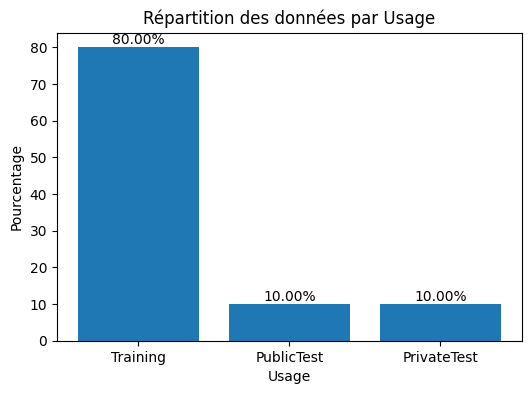

In [ ]:
# Bibliothèque de visualisation
import matplotlib.pyplot as plt

# Calculer le nombre d'occurrence de chaque classe de la colonne 'Usage'
 # Index : Noms des classes : Training, PublicTest, PrivateTest
 # Valeur : Nombre d'images par classe
counts = df['Usage'].value_counts()

# Transformer les valeurs en proportions
percentages = counts / counts.sum() * 100

# Créer une figure et un bar plot
plt.figure(figsize=(6, 4))
# Chaque barre représente une classe avec sa proportion
bars = plt.bar(counts.index , percentages)

# Parcourir chaque barre
for bar in bars :
   # Récupèrer la hauteur de chaque barre
  yval = bar.get_height()

  plt.text(
       bar.get_x() + bar.get_width() / 2 , # Centre horizontal
      yval,  # Position verticale
      f'{yval:.2f}%', # Texte affiché
      ha='center', va='bottom' # Alignement horizontal + au-dessus de la barre
      )

plt.xlabel('Usage')
plt.ylabel('Pourcentage')
plt.title('Répartition des données par Usage')
plt.show()


# Affichage d'une seule image

In [ ]:
import numpy as np


In [ ]:
# Prendre la première image
image = df['pixels'][0]

# Convertir string -> vecteur
image = np.fromstring(image, dtype=int, sep=' ')

# Transformer en matrice (48,48)
image = image.reshape(48,48)

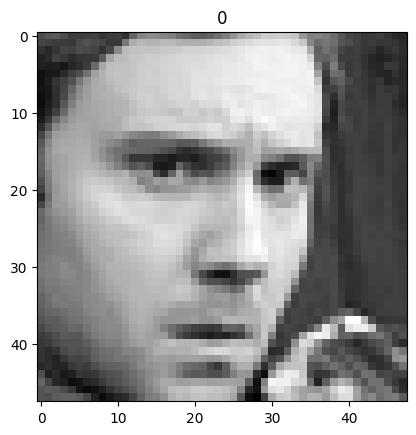

In [ ]:
# Bibliothèque pour affichage des graphiques et images
import matplotlib.pyplot as plt

# Afficher l'image sous forme de matrice (niveaux de gris)
plt.imshow(image , cmap="gray")

# Afficher l'émotion correspondant
plt.title(df['emotion'][0])

# Afficher l'image à l'écran
plt.show()

In [ ]:
# Liste pour stocker toutes les images transformées
images =  []

# Parcourir chaque ligne de la colonne 'pixels'
for pixel_sequence in df['pixels'] :

  # Convertir la string de pixels en vecteur
  image = np.fromstring(pixel_sequence, dtype=int, sep=' ')

  # Transformer le vecteur en image 48*48
  image = image.reshape(48,48)

  # Ajouter l'image à la liste
  images.append(image)

# Pourquoi convertir une liste en un tableau NumPy (array) ?


1.   Performance : beaucoup plus rapide
2.   Compatibilité avec les modèles : les modèles (PyTorch/TensorFlow) attendent des tensors ou NumPy arrays
3.   Opérations mathématiques : l'opération X = X / 255.0 marche directement avec NumPy




In [ ]:
# Convertir en tableau NumPy
X = np.array(images)

# Afficher le shape de X
print(X.shape)

(35887, 48, 48)


to_numpy() : pandas Series/DataFrame -> NumPy array

np.array() : structure itérable Python -> NumPyArray

In [ ]:
# Convertir une Series pandas en un NumPy array
Y = df['emotion'].to_numpy()
print(Y.shape)

(35887,)


# Affichage de plusieurs images dans le dataset

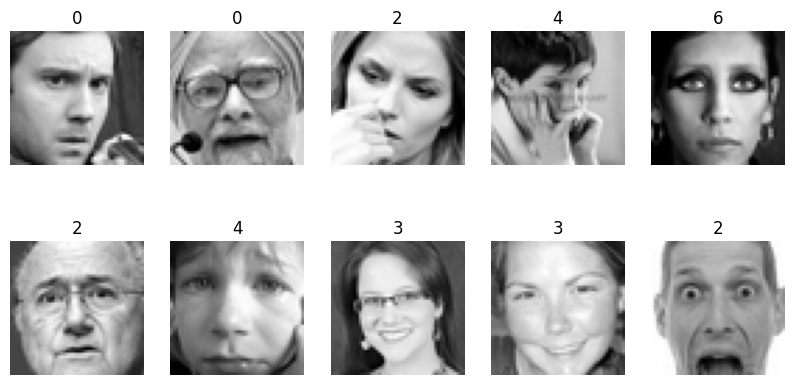

In [ ]:
# Créer une figure globale (taille 5*5)
plt.figure(figsize=(10,5))

# Parcourir les 10 premières images
for i in range(10) :

  # Découper la figure en une grille (2*5)
  # Chaque itération on choisit une case spécifique pour afficher une image et son label
  plt.subplot(2,5,i+1)

  plt.imshow(X[i], cmap="gray")
  plt.title(Y[i])
  plt.axis('off')

plt.show()

# Preprocessing


## Normalisation
### 🔹 Normalisation des données d’entrée

Dans notre dataset, les pixels des images prennent des valeurs dans l’intervalle :

$$
x \in [0, 255]
$$

Afin de stabiliser l’apprentissage, on applique une normalisation :

$$
x' = \frac{x}{255}
\quad \Rightarrow \quad
x' \in [0,1]
$$

---

### 🔸 1. Impact sur la propagation avant

Dans une couche neuronale :

$$
z = w \cdot x + b
$$

Si $x$ est grand, alors $z$ peut prendre des valeurs élevées, ce qui influence le comportement des fonctions d’activation.

---

### 🔸 2. Impact sur la rétropropagation

Le gradient par rapport aux poids est donné par :

$$
\frac{\partial L}{\partial w}
= \frac{\partial L}{\partial a}
\cdot \frac{\partial a}{\partial z}
\cdot \frac{\partial z}{\partial w}
$$

Or :

$$
\frac{\partial z}{\partial w} = x
$$

Donc :

$$
\frac{\partial L}{\partial w}
= \frac{\partial L}{\partial a}
\cdot \frac{\partial a}{\partial z}
\cdot x
$$

👉 Le gradient est donc proportionnel à la valeur de l’entrée $x$.

---

### 🔸 3. Cas sans normalisation ($x \in [0,255]$)

#### ✔️ Avec ReLU

$$
\text{ReLU}(z) = \max(0, z)
$$

$$
\frac{\partial a}{\partial z} =
\begin{cases}
1 & \text{si } z > 0 \\
0 & \text{sinon}
\end{cases}
$$

Donc :

$$
\frac{\partial L}{\partial w}
= \frac{\partial L}{\partial a} \cdot x
$$

👉 Si $x$ est grand :

* le gradient devient grand
* les mises à jour des poids sont importantes
* l’apprentissage devient instable

---

#### ✔️ Avec Sigmoid

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

$$
\sigma'(z) = \sigma(z)(1 - \sigma(z))
$$

Si $z$ est grand :

$$
\sigma'(z) \approx 0
$$

Donc :

$$
\frac{\partial L}{\partial w} \approx 0
$$

👉 phénomène de **vanishing gradient**

---

### 🔸 4. Cas avec normalisation ($x \in [0,1]$)

Après normalisation :

* les valeurs de $z$ restent dans une plage contrôlée
* les fonctions d’activation opèrent dans une zone stable
* le terme $x$ est réduit

Donc :  $\frac{\partial L}{\partial w}$ est mieux conditionné

---

### 🔸 5. Conclusion

La normalisation des données d’entrée permet de :

* réduire l’amplitude des entrées
* éviter la saturation des fonctions d’activation
* contrôler l’échelle des gradients
* stabiliser les mises à jour des poids
* améliorer la convergence du modèle

Elle constitue ainsi une étape essentielle pour garantir un apprentissage efficace et stable.


In [ ]:
# Normalisation des pixels : on ramène les valeurs de [0, 255] à [0, 1]
X = X / 255.0

# Vérifier la forme du dataset après normalisation
print(X.shape)

(35887, 48, 48)


## Reshape

In [ ]:
# Adaptation du format des données pour un réseau de neurones convolutif (CNN)
# Les CNN attendent des entrées sous la forme (batch_size, height, width, channels)
# Ici :
# - batch_size : nombre d'images (-1 pour inférer automatiquement)
# - height = 48, width = 48
# - channels = 1 (images en niveaux de grix)
X = X.reshape(-1 ,48 , 48 , 1)

# Vérification de la nouvelle structure des données
print(X.shape)

(35887, 48, 48, 1)


# One-hot encoding
*   Un entier (0-6) introduit une idée de relation numérique
*   Cette relation peut etre interprétée comme un ordre ou une distance
*   Ce qui est faux pour des classes comme les émotions

**Exemple concret :**  Si on utilise :
*   0 = angry
*   1 = happy
*   2 = sad

Le modèle peut apprendre happy(1) est **plus proche** de sad(2) que angry(0).
Mais en réalité, ces classes n'ont aucune distance logique.

**Solution :**

*   angry → [1,0,0,0,0,0,0]
*   happy → [0,1,0,0,0,0,0]
*   sad   → [0,0,1,0,0,0,0]

✅ pas d’ordre

✅ pas de distance implicite

✅ chaque classe est indépendante




In [ ]:
# Fonction pour one-hot encoding
from tensorflow.keras.utils import to_categorical

# Transformer les labels en format one-hot (7 classes d'émotions)
Y_onehot = to_categorical(Y , num_classes = 7)

# Vérifier la nouvelle Forme de données
print(Y_onehot.shape)

(35887, 7)


# Split du dataset
## Boolean mask
df['Usage'] == 'Training' : retourne une séries booléenne (masque)

Exemple :

*   0  True
*   1  False
*   2  False
*   ...

Pour chaque ligne :
*  True → appartient à Training
*  False → n’appartient pas à Training

### Ensuite : X[train_idx]  
 * garde les lignes où train_idx == True
 * ignore les False

In [ ]:
# Données d'entraînement
# Utilisées pour apprendre les poids du modèle
train_idx = df['Usage'] == 'Training'
X_train  = X[train_idx]
Y_onehot_train = Y_onehot[train_idx]


In [ ]:
# Données de validation
# Utilisées pour ajuster les hyperparamètres et surveiller l'overfitting
val_idx = df['Usage'] == 'PublicTest'
X_val  = X[val_idx]
Y_onehot_val = Y_onehot[val_idx]

In [ ]:
# Données de test final
# Utilisées uniquement pour l'évaluation finale du modèle (jamais pendant l'entraînement)
test_idx = df['Usage'] == 'PrivateTest'
X_test = X[test_idx]
Y_onehot_test = Y_onehot[test_idx]

### Vérification des dimensions

In [ ]:
print("Shape X_train :", X_train.shape)
print("Shape Y_train :", Y_onehot_train.shape)


Shape X_train : (28709, 48, 48, 1)
Shape Y_train : (28709, 7)


In [ ]:
print("Shape X_val   :", X_val.shape)
print("Shape Y_val   :", Y_onehot_val.shape)

Shape X_val   : (3589, 48, 48, 1)
Shape Y_val   : (3589, 7)


In [ ]:
print("Shape X_test  :", X_test.shape)
print("Shape Y_test   :", Y_onehot_test.shape)

Shape X_test  : (3589, 48, 48, 1)
Shape Y_test   : (3589, 7)


In [ ]:
# Chemin du dossier processed
processed_data_path = base_path + "data/processed/"

# Sauvegarder les données
pd.to_pickle(X_train, processed_data_path + "X_train.pkl")
pd.to_pickle(Y_onehot_train, processed_data_path + "Y_train.pkl")

pd.to_pickle(X_val, processed_data_path + "X_val.pkl")
pd.to_pickle(Y_onehot_val, processed_data_path + "Y_val.pkl")

pd.to_pickle(X_test, processed_data_path + "X_test.pkl")
pd.to_pickle(Y_onehot_test, processed_data_path + "Y_test.pkl")
